In [2]:
from google.colab import files
files.upload()  # select kaggle.json from your computer

!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d ravirajsinh45/real-life-industrial-dataset-of-casting-product -p /content/data --unzip
!find /content/data -maxdepth 3 -type d

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 100M/100M [00:00<00:00, 108MB/s] 

/content/data
/content/data/casting_512x512
/content/data/casting_512x512/casting_512x512
/content/data/casting_512x512/casting_512x512/ok_front
/content/data/casting_512x512/casting_512x512/def_front
/content/data/casting_data
/content/data/casting_data/casting_data
/content/data/casting_data/casting_data/train
/content/data/casting_data/casting_data/test


In [12]:
import os, glob

base = "/content/data/casting_data/casting_data"
for split in ["train", "test"]:
    for cls in ["def_front", "ok_front"]:
        n = len(glob.glob(f"{base}/{split}/{cls}/*.jpeg"))
        print(f"{split}/{cls}: {n} images")

train/def_front: 3758 images
train/ok_front: 2875 images
test/def_front: 453 images
test/ok_front: 262 images


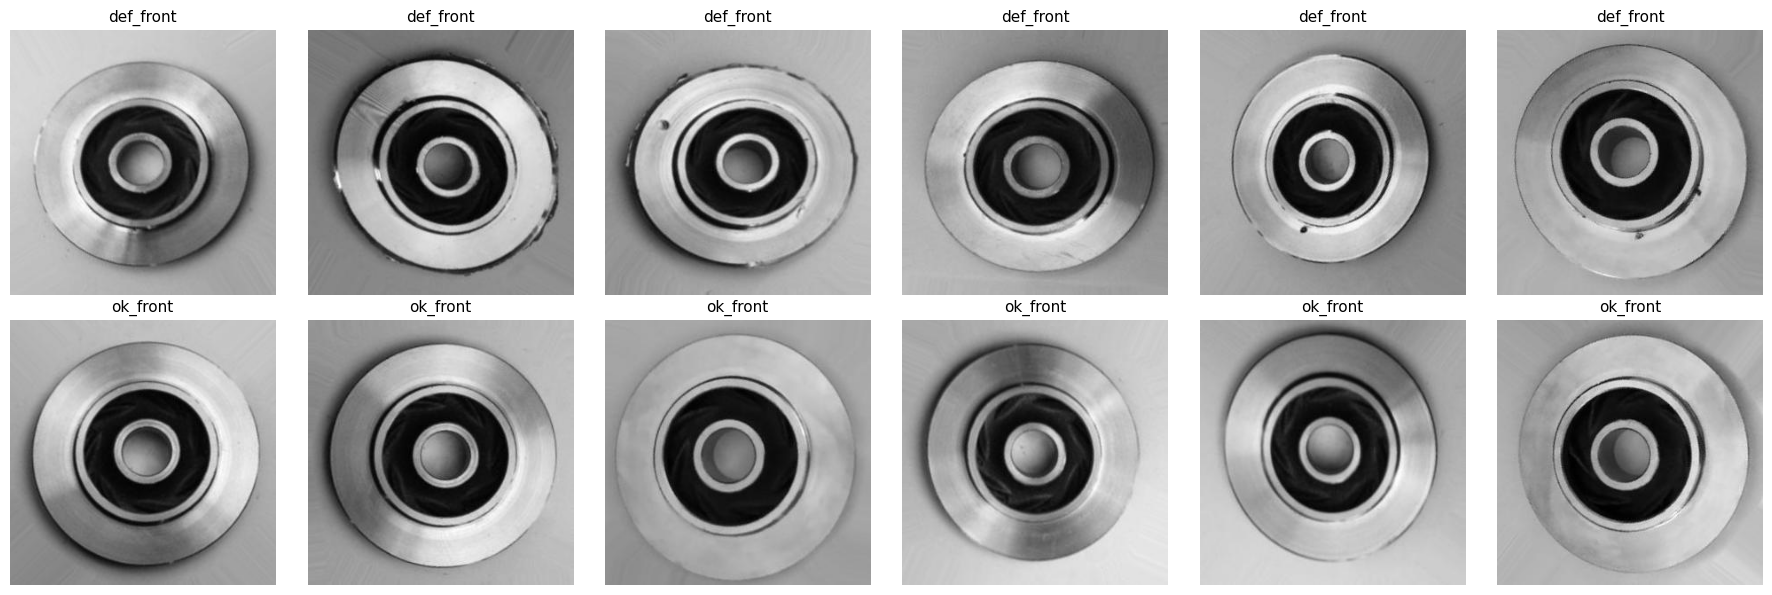

In [13]:
import glob, random
import matplotlib.pyplot as plt
from PIL import Image

base = "/content/data/casting_data/casting_data/train"
random.seed(42)

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for row, cls in enumerate(["def_front", "ok_front"]):
    files = random.sample(glob.glob(f"{base}/{cls}/*.jpeg"), 6)
    for col, f in enumerate(files):
        ax = axes[row, col]
        ax.imshow(Image.open(f), cmap="gray")
        ax.set_title(cls, fontsize=11)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [14]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
base = "/content/data/casting_data/casting_data"

train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

full_train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
test_set = datasets.ImageFolder(f"{base}/test", transform=eval_tf)

# Hold out 15% of the training data for validation
val_size = int(0.15 * len(full_train))
train_size = len(full_train) - val_size
train_set, val_set = random_split(full_train, [train_size, val_size],
                                  generator=torch.Generator().manual_seed(42))
# Validation should use the eval transform, not the augmented one
val_set.dataset = datasets.ImageFolder(f"{base}/train", transform=eval_tf)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print("Classes:", full_train.classes)
print("Train:", len(train_set), "| Val:", len(val_set), "| Test:", len(test_set))

Classes: ['def_front', 'ok_front']
Train: 5639 | Val: 994 | Test: 715


In [15]:
import torch.nn as nn
from torchvision import models

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Pretrained ResNet18, with the final layer replaced for 2 classes
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def run_epoch(loader, train=False):
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

best_val_loss = float("inf")
for epoch in range(1, 6):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader)
    print(f"Epoch {epoch}: train loss {tr_loss:.4f}, acc {tr_acc:.3f} | "
          f"val loss {va_loss:.4f}, acc {va_acc:.3f}")
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(model.state_dict(), "/content/best_resnet18.pt")

print("Saved best model (lowest validation loss)")

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 114MB/s]


Epoch 1: train loss 0.0521, acc 0.984 | val loss 0.0232, acc 0.994
Epoch 2: train loss 0.0170, acc 0.994 | val loss 0.0218, acc 0.994
Epoch 3: train loss 0.0132, acc 0.995 | val loss 0.0091, acc 0.998
Epoch 4: train loss 0.0106, acc 0.996 | val loss 0.0070, acc 0.997
Epoch 5: train loss 0.0082, acc 0.997 | val loss 0.0133, acc 0.997
Saved best model (lowest validation loss)


In [16]:
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

model.load_state_dict(torch.load("/content/best_resnet18.pt"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(y.numpy())

all_preds, all_labels = np.array(all_preds), np.array(all_labels)

print(classification_report(all_labels, all_preds,
                            target_names=test_set.classes, digits=3))

cm = confusion_matrix(all_labels, all_preds)
print("Confusion matrix (rows = true, columns = predicted):")
print(f"                 pred def   pred ok")
print(f"true def_front   {cm[0,0]:>8}   {cm[0,1]:>8}")
print(f"true ok_front    {cm[1,0]:>8}   {cm[1,1]:>8}")

              precision    recall  f1-score   support

   def_front      1.000     0.993     0.997       453
    ok_front      0.989     1.000     0.994       262

    accuracy                          0.996       715
   macro avg      0.994     0.997     0.995       715
weighted avg      0.996     0.996     0.996       715

Confusion matrix (rows = true, columns = predicted):
                 pred def   pred ok
true def_front        450          3
true ok_front           0        262


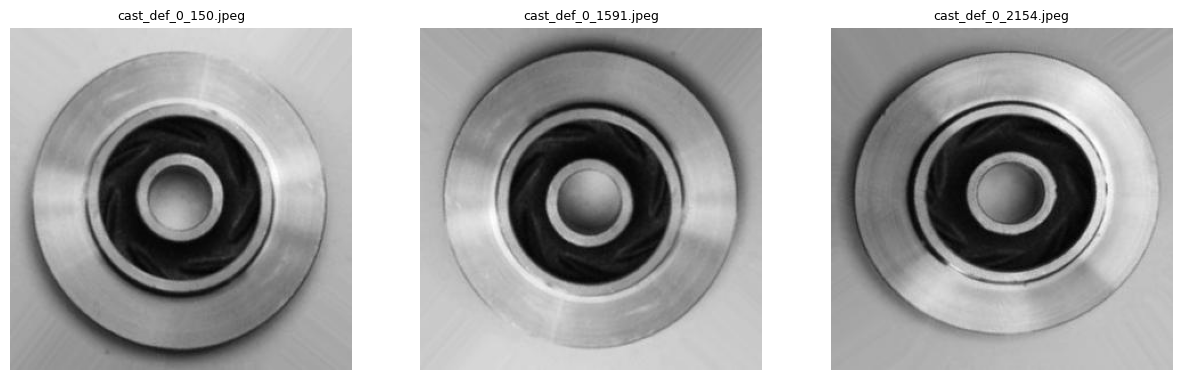

In [17]:
import torch
import matplotlib.pyplot as plt
from PIL import Image

model.eval()
missed = []
idx = 0
with torch.no_grad():
    for x, y in test_loader:
        preds = model(x.to(device)).argmax(1).cpu()
        for i in range(len(y)):
            if y[i] == 0 and preds[i] == 1:  # true defect, predicted OK
                missed.append(test_set.samples[idx + i][0])
        idx += len(y)

fig, axes = plt.subplots(1, len(missed), figsize=(5 * len(missed), 5))
for ax, f in zip(axes, missed):
    ax.imshow(Image.open(f), cmap="gray")
    ax.set_title(f.split("/")[-1], fontsize=9)
    ax.axis("off")
plt.show()

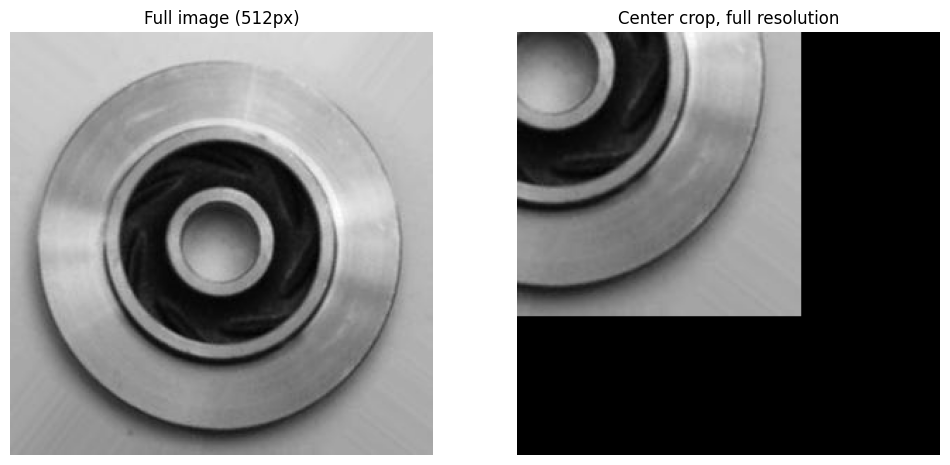

In [18]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(missed[0])
crop = img.crop((128, 128, 384, 384))  # central 256x256 region at full resolution

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("Full image (512px)"); axes[0].axis("off")
axes[1].imshow(crop, cmap="gray"); axes[1].set_title("Center crop, full resolution"); axes[1].axis("off")
plt.show()

Image size: (300, 300)


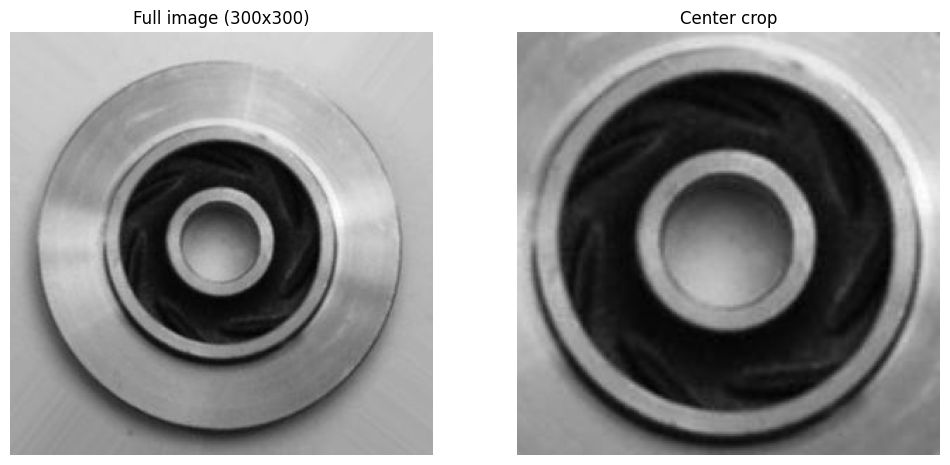

In [19]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(missed[0])
w, h = img.size
print("Image size:", img.size)

# Crop the central 60% of the image, using its real dimensions
cw, ch = int(w * 0.6), int(h * 0.6)
left, top = (w - cw) // 2, (h - ch) // 2
crop = img.crop((left, top, left + cw, top + ch))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img, cmap="gray"); axes[0].set_title(f"Full image ({w}x{h})"); axes[0].axis("off")
axes[1].imshow(crop, cmap="gray"); axes[1].set_title("Center crop"); axes[1].axis("off")
plt.show()

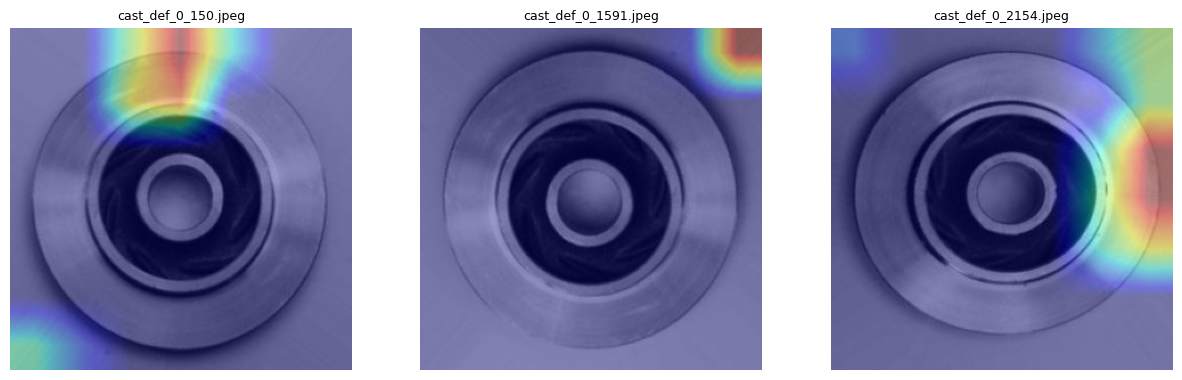

In [20]:
import torch, numpy as np, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

acts, grads = {}, {}
layer = model.layer4[-1]
layer.register_forward_hook(lambda m, i, o: acts.update(a=o))
layer.register_full_backward_hook(lambda m, gi, go: grads.update(g=go[0]))

def gradcam(path):
    img = Image.open(path)
    x = eval_tf(img).unsqueeze(0).to(device)
    model.eval()
    out = model(x)
    model.zero_grad()
    out[0, 0].backward()  # class 0 = def_front
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=img.size[::-1], mode="bilinear")[0, 0]
    cam = cam.detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return np.array(img.convert("L")), cam

fig, axes = plt.subplots(1, len(missed), figsize=(5 * len(missed), 5))
for ax, f in zip(axes, missed):
    gray, cam = gradcam(f)
    ax.imshow(gray, cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4)
    ax.set_title(f.split("/")[-1], fontsize=9)
    ax.axis("off")
plt.show()